# 2. 평점 + 리뷰 텍스트

| 세부 기능 | 판매자 질문 예시 | 도구 |
| --- | --- | --- |
| 2-1 별점 요약 + 불만 유형 | "1점 리뷰들 왜 그래?" | `review_summary` |
| 2-2 리뷰 번역·답글 초안 | "이 리뷰 무슨 뜻이야? 답글 써줘" | `review_examples` + LLM |
| 2-3 1~2점 위험 주문 | "나쁜 리뷰 받을 것 같은 주문?" | `low_review_risk` |
| 2-4 나쁜 리뷰의 값 | "1점 하나가 얼마나 손해야?" | `review_cost` |
| 2-5 묶음 주문 경고 | "여러 개 주문은 왜 별점이 낮아?" | 정리 테이블로 바로 계산 |

**실행법 (Colab)**: GitHub 저장소(jc020230/BDA)에서 이 노트북을 Colab으로 열고 위에서부터 실행하면 돼요. 첫 셀이 저장소를 자동으로 내려받아서 `seller_tools.py`와 `preprocessing/` 폴더의 데이터를 찾아요. 노트북끼리는 서로 독립이라 아무거나 먼저 열어도 돼요.

**아래 "챗봇이 이렇게 말할 수 있어요"** 문장은 도구 결과 숫자로 자동으로 만든 예시예요. 실제 챗봇에서는 LLM이 이 결과를 받아 자연스럽게 말해요.

In [1]:
# 준비: 저장소 파일(seller_tools.py, 전처리 데이터)을 찾고, 없으면 GitHub에서 내려받기
import os, sys, json, zipfile, subprocess
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/jc020230/BDA.git'
DATA_DIRS = ['olist_mart', 'preprocessing', '/content/drive/MyDrive/olist_mart']
has_data = lambda p: os.path.exists(f'{p}/orders_mart.parquet')

# Colab에서 GitHub 노트북만 열면 다른 파일이 없어서, 저장소를 통째로 내려받아 그 폴더로 이동
if not os.path.exists('seller_tools.py'):
    if not os.path.exists('BDA/seller_tools.py'):
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, 'BDA'], check=True)
    os.chdir('BDA')
MART_DIR = next((p for p in DATA_DIRS if has_data(p)), None)
if MART_DIR is None:   # 저장소에 데이터가 없으면 zip이나 드라이브에서 찾기
    z = next((p for p in ['olist_mart_v2_github.zip', 'olist_mart_v2.zip', 'olist_mart.zip'] if os.path.exists(p)), None)
    if z: zipfile.ZipFile(z).extractall('.'); MART_DIR = 'olist_mart'
    elif IN_COLAB:
        from google.colab import drive; drive.mount('/content/drive'); MART_DIR = next(p for p in DATA_DIRS if has_data(p))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from seller_tools import SellerTools, TOOLS, setup_korean_font
setup_korean_font()
st = SellerTools(MART_DIR)
if st.evm_table is None:
    print('⚠️ 전처리 1판 결과예요. 2판을 쓰면 이벤트 배수 표와 도착 전 리뷰 기능까지 쓸 수 있어요.')

def show(result, limit=1500):
    """도구 결과(JSON)를 보기 좋게 출력"""
    text = json.dumps(result, ensure_ascii=False, indent=1)
    print(text if len(text) <= limit else text[:limit] + '\n... (생략)')

DEMO = '2eb70248'                  # 시계·선물, 별점 낮고 발송이 느린 판매자 (앞 8자리만 써도 됨)
BIG = st.ss.orders.idxmax()        # 주문이 가장 많은 판매자
print('도구', len(TOOLS), '개 준비 완료 | 작업 폴더:', os.getcwd(), '| 데이터:', MART_DIR)

도구 23 개 준비 완료 | 작업 폴더: /tmp/repo_asof | 데이터: preprocessing


## 2-1. 별점 요약 + 불만 유형 (동종 카테고리와 비교)
불만 유형은 포르투갈어 키워드 규칙으로 분류했어요: 못 받음, 지연, 다른 상품, 불량·파손, 일부만 옴, 품질·가품.

{
 "seller_id": "2eb70248d66e0e3ef83659f71b244378",
 "reviews": 193,
 "avg_score": 2.6736,
 "score_distribution": {
  "1": 0.4093,
  "2": 0.0984,
  "3": 0.1347,
  "4": 0.1244,
  "5": 0.2332
 },
 "low_reviews_with_text": 87,
 "complaint_share_mine": {
  "못 받음": 0.1494,
  "지연": 0.1264,
  "다른 상품": 0.1954,
  "불량·파손": 0.1609,
  "일부만 옴": 0.0115,
  "품질·가품": 0.092
 },
 "complaint_share_category": {
  "못 받음": 0.2772,
  "지연": 0.1403,
  "다른 상품": 0.0528,
  "불량·파손": 0.0677,
  "일부만 옴": 0.0413,
  "품질·가품": 0.1023
 },
 "top_complaint": {
  "type": "다른 상품",
  "share": 0.1954
 },
 "reviews_counting_days": 1
}


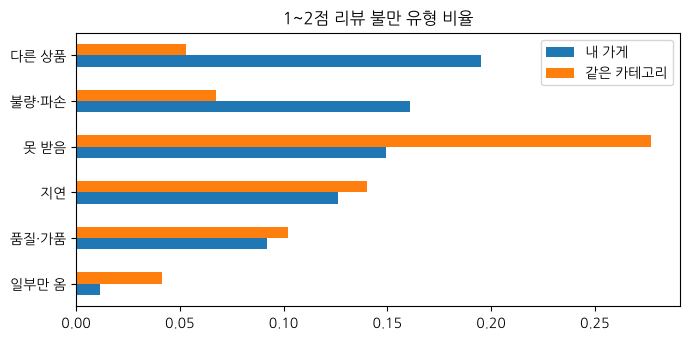

💬 평균 별점 2.67점이에요. 1~2점 리뷰 87개 중 가장 많은 불만은 '다른 상품' 20%이고, 같은 카테고리 평균(5%)보다 높아요.


In [2]:
r = st.call('review_summary', {'seller_id': DEMO})
show(r)
cmp = pd.DataFrame({'내 가게': r['complaint_share_mine'], '같은 카테고리': r['complaint_share_category']})
ax = cmp.sort_values('내 가게').plot(kind='barh', figsize=(7, 3.5)); ax.set_title('1~2점 리뷰 불만 유형 비율'); plt.tight_layout(); plt.show()
top = r['top_complaint']
print('💬', f"평균 별점 {r['avg_score']:.2f}점이에요. 1~2점 리뷰 {r['low_reviews_with_text']}개 중 가장 많은 불만은 '{top['type']}' {top['share']:.0%}이고, "
      f"같은 카테고리 평균({r['complaint_share_category'][top['type']]:.0%})보다 높아요.")

## 2-2. 리뷰 번역·요약·답글 초안
도구는 **원문(포르투갈어)**만 돌려주고, 번역·요약·답글은 챗봇의 LLM이 해요. 아래는 LLM에 같이 넘길 지시문 예시예요.

In [3]:
r = st.call('review_examples', {'seller_id': DEMO, 'complaint': '다른 상품', 'n': 3})
show(r)
PROMPT = """아래는 브라질 고객의 포르투갈어 리뷰야.
1) 한국어로 번역해줘. 2) 불만 핵심을 한 줄로 요약해줘.
3) 판매자 입장에서 정중한 포르투갈어 답글 초안(3문장 이내)을 쓰고, 한국어 뜻도 같이 보여줘.
리뷰: {message}"""
print('\n[LLM에 넘길 지시문 예시]\n' + PROMPT.format(message=r['examples'][0]['message_pt']))

{
 "seller_id": "2eb70248d66e0e3ef83659f71b244378",
 "examples": [
  {
   "order_id": "8081c44895cefcfebc13faec5c9ed8bf",
   "score": 2,
   "date": "2018-08-02",
   "title": "Relógios errados ",
   "message_pt": "Os relógios veio com modelos diferentes do que tinha comprado pelo site. Só não vou devolve los pelo fato de ter que usar na minha viagem.",
   "complaints": [
    "다른 상품"
   ]
  },
  {
   "order_id": "74fedc6aa056c9359846751fe21a8676",
   "score": 1,
   "date": "2018-07-28",
   "title": "Produto falsificado ",
   "message_pt": "Comprei o relógio casio rose Gold e o que chegou é completamente diferente da imagem, após fazer umas pesquisas na internet descobri que se trata de uma replica. Fiquei bastante chateada com a compra.",
   "complaints": [
    "다른 상품",
    "품질·가품"
   ]
  },
  {
   "order_id": "f3513eec8f1434b5b7e04ddf3598df40",
   "score": 1,
   "date": "2018-07-28",
   "title": "Produto errado",
   "message_pt": "Não recebi o produto que comprei, chegou outro modelo me

## 2-3. 1~2점 위험 주문
"지연 구간 × 묶음 주문 여부"별 과거 1~2점 비율로 위험 순위를 매겨요. 과거 데이터라 배송 후 정보를 쓰지만, 실서비스에서는 1번 메뉴의 예측된 지연을 넣으면 돼요.

In [4]:
r = st.call('low_review_risk', {'seller_id': BIG, 'top_n': 8})
pd.DataFrame(r['orders'])

,order_id,risk,delay_bin,n_items,actual_score,reason
0,5295a4f70cac6082f1f9051409e69010,0.4287,2~3일 늦음,1,3.0,2~3일 늦음
1,b300e160f5892169bafa006e670a43f5,0.4287,2~3일 늦음,1,5.0,2~3일 늦음
2,4c480567d1db63cffddc552638c35d8f,0.2474,일찍 옴,3,2.0,묶음 주문
3,16a811fb1fdf869b3b5ab6f91b6f36bb,0.1186,당일,1,5.0,당일
4,0006ec9db01a64e59a68b2c340bf65a7,0.0754,일찍 옴,1,5.0,일반
5,17cc50afa3f8797f14bf500a65230845,0.0754,일찍 옴,1,5.0,일반
6,1dfe970583e8a1a09241aa32a815a5b4,0.0754,일찍 옴,1,2.0,일반
7,232efaeba12fd576e70a88f09d6583b6,0.0754,일찍 옴,1,5.0,일반


## 2-4. 나쁜 리뷰의 값
같은 상품이 1~2점 리뷰를 받은 뒤 4주 판매가 5점 리뷰 뒤보다 **약 6.1% 더 줄었다**는 분석(신뢰구간 0.4~12.5%)으로 계산해요. 주문 20건 이상 상품은 그 상품 값, 아니면 카테고리 중앙값을 써요.

In [5]:
rel = st.ps[st.ps.reliable]
popular = rel.iloc[(rel.bad_review_cost - rel.bad_review_cost.median()).abs().argsort().iloc[0]].product_id   # 손해액이 중간쯤인 '보통' 상품
r = st.call('review_cost', {'product_id': popular})
show(r)
print('💬', f"이 상품({r['category']})은 한 달에 약 {r['monthly_units']:.0f}개 팔려서, 1~2점 리뷰 하나가 다음 한 달 매출을 약 {r['bad_review_cost']:.0f}헤알 깎을 수 있어요.")

{
 "product_id": "473795a355d29305c3ea6b156833adf5",
 "category": "향수",
 "monthly_units": 4.3909,
 "median_price": 55.9,
 "bad_review_cost": 14.9725,
 "cost_basis": "상품 자체 값",
 "note": "1~2점 리뷰 뒤 4주 판매가 5점 리뷰 뒤보다 약 6.1% 더 줄었다는 분석 결과로 계산 (신뢰구간 0.4~12.5%)"
}
💬 이 상품(향수)은 한 달에 약 4개 팔려서, 1~2점 리뷰 하나가 다음 한 달 매출을 약 15헤알 깎을 수 있어요.


## 2-5. 묶음 주문 경고
약속대로 도착해도 **상품이 여러 개인 주문은 1~2점이 많아요.** 리뷰를 보면 "일부만 왔다"는 불만이 많아요.

In [6]:
d = st.delivered.assign(n_items_group=lambda x: x.n_items.clip(upper=3).map({1: '1개', 2: '2개', 3: '3개 이상'}))
t = d.groupby(['late', 'n_items_group']).low_review.mean().unstack()
t.index = ['약속 지킴', '약속 어김']
print('1~2점 비율'); print(t.round(3))
mine = st.valid[st.valid.seller_id == st._sid(BIG)]
print('\n💬', f"제때 와도 상품 2개 주문은 1~2점이 {t.loc['약속 지킴', '2개']:.0%}, 1개 주문은 {t.loc['약속 지킴', '1개']:.0%}예요. "
      f"내 주문 중 {(mine.n_items > 1).mean():.0%}가 묶음 주문이니, 분할 배송이면 미리 안내하세요.")

1~2점 비율
n_items_group     1개     2개  3개 이상
약속 지킴          0.076  0.233  0.295
약속 어김          0.633  0.657  0.676

💬 제때 와도 상품 2개 주문은 1~2점이 23%, 1개 주문은 8%예요. 내 주문 중 8%가 묶음 주문이니, 분할 배송이면 미리 안내하세요.


## (선택) 리뷰 글 자동 분류 (딥러닝 파트)
`predictor_experiments.ipynb`의 실험 F에서 리뷰 글로 1~2점을 맞히는 분류기를 비교했어요 (TF-IDF + 로지스틱 회귀 시험 AUC 0.954). 포르투갈어 BERT(BERTimbau) 미세조정 코드도 거기에 있어요 (Colab GPU 필요).